<a href="https://colab.research.google.com/github/azamatumirzakov555/---/blob/main/Ruchki.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1.Подсчет ручек

In [1]:
import os
VIDEO = "/content/WhatsApp Video 2026-10-11 at 11.10.06 PM.mp4"
print(round(os.path.getsize(VIDEO) / 1e6, 2), "MB")      # ожидаю около 5 MB

!rm -rf /content/frames && mkdir -p /content/frames
!ffmpeg -y -loglevel error -i "/content/WhatsApp Video 2026-10-11 at 11.10.06 PM.mp4" -vf fps=10 -q:v 2 /content/frames/%04d.jpg
!ls /content/frames | wc -l                               # ожидаю около 415

5.04 MB
415


Кадров: 415
Размер кадра: (1024, 576, 3)


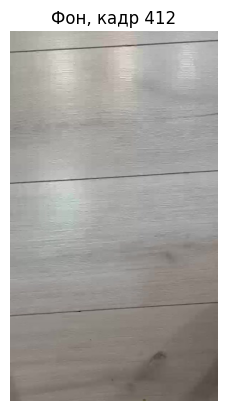

In [2]:
import cv2, glob, time
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import medfilt

import os, glob, subprocess, shutil, time
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import medfilt

FPS_OUT = 10
files = sorted(glob.glob("/content/frames/*.jpg"))
print("Кадров:", len(files))

def get_frame(k):
    return cv2.imread(files[k])

BG_IDX = len(files) - 3        # кадр, где стол пустой и без руки
bg = get_frame(BG_IDX)
print("Размер кадра:", bg.shape)

plt.imshow(cv2.cvtColor(bg, cv2.COLOR_BGR2RGB))
plt.title(f"Фон, кадр {BG_IDX}"); plt.axis("off"); plt.show()

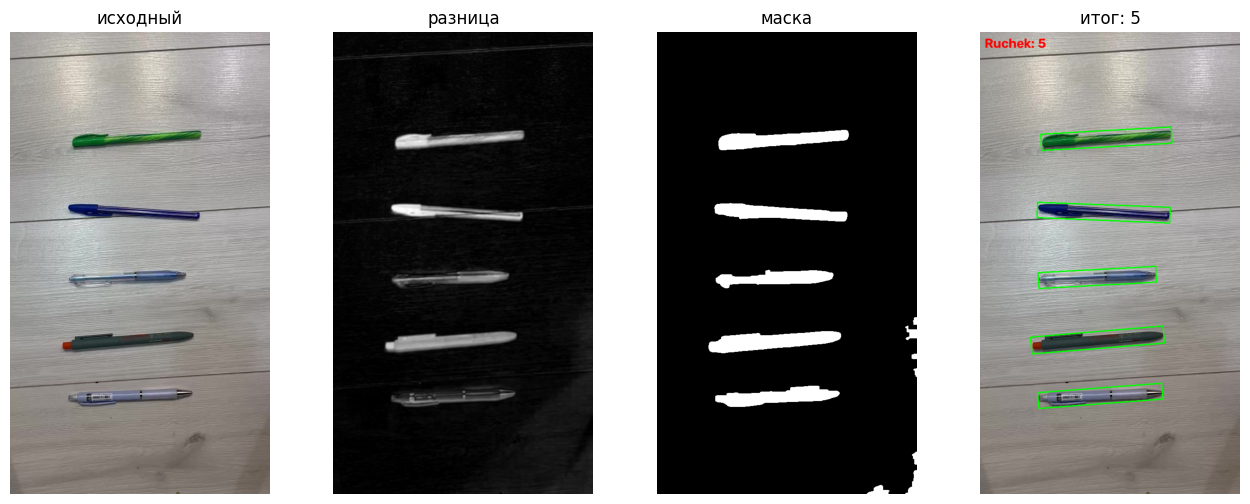

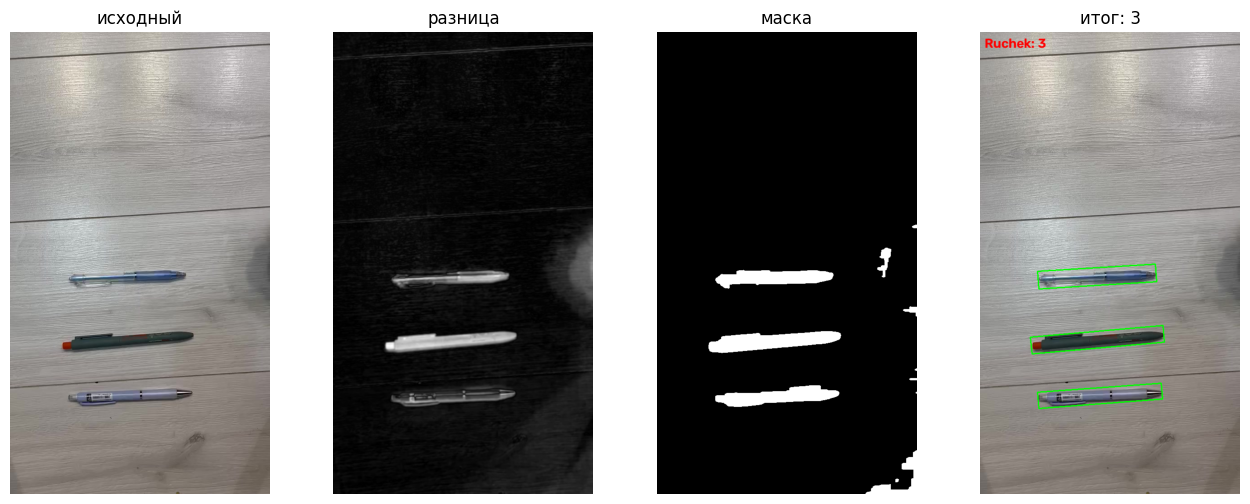

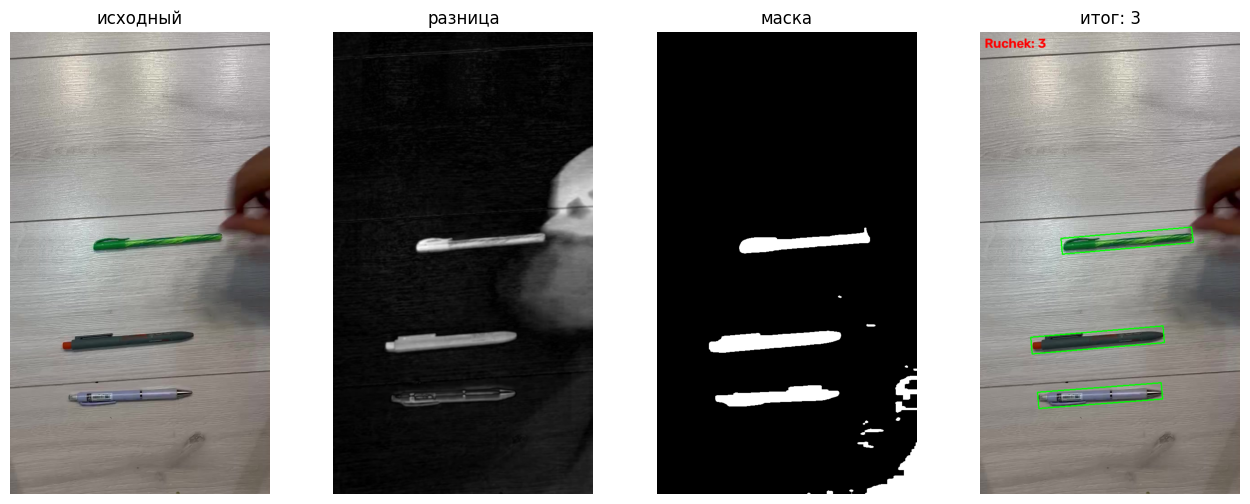

In [3]:
BLUR = (7, 7)
DIFF_T = 22        # порог разницы с фоном
MIN_AREA = 300
MIN_RATIO = 3.5    # длина/ширина
MIN_FILL = 0.6
BORDER = 5

kernel_open  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (25, 9))       # склеивает куски ручки
kernel_blob  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (61, 61))   # шире ручки: рука, тень
kernel_grow  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))

bg_f = cv2.GaussianBlur(bg, BLUR, 0).astype(np.float32)
bg_med = np.median(bg_f.reshape(-1, 3), axis=0)

def count_objects(frame):
    fb = cv2.GaussianBlur(frame, BLUR, 0).astype(np.float32)
    gain = np.median(fb.reshape(-1, 3), axis=0) / bg_med                   # выравнивание яркости
    diff = np.clip(np.abs(fb - bg_f * gain).max(axis=2), 0, 255).astype(np.uint8)
    mask = (diff > DIFF_T).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open)             # убрать шум

    # убираем крупные пятна (рука + тень), тонкие ручки остаются
    big = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_blob)
    mask = cv2.bitwise_and(mask, cv2.bitwise_not(cv2.dilate(big, kernel_grow)))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open)

    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel_close)           # склеить куски ручки

    H, W = mask.shape
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out, count = frame.copy(), 0
    for c in contours:
        if cv2.contourArea(c) < MIN_AREA:
            continue
        x, y, bw, bh = cv2.boundingRect(c)
        if x <= BORDER or y <= BORDER or x + bw >= W - BORDER or y + bh >= H - BORDER:
            continue
        (cx, cy), (w, h), ang = cv2.minAreaRect(c)
        ratio = max(w, h) / max(min(w, h), 1)
        fill = cv2.contourArea(cv2.convexHull(c)) / max(w * h, 1)
        if ratio < MIN_RATIO or fill < MIN_FILL:
            continue
        count += 1
        box = cv2.boxPoints(((cx, cy), (w, h), ang)).astype(int)
        cv2.drawContours(out, [box], 0, (0, 255, 0), 2)
    cv2.putText(out, f"Ruchek: {count}", (10, 35), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
    return count, out, diff, mask

for sec in [1, 16, 24]:
    f = get_frame(int(sec * FPS_OUT))
    n, out, diff, mask = count_objects(f)
    fig, ax = plt.subplots(1, 4, figsize=(16, 6))
    for a, im, t in zip(ax, [f, diff, mask, out], ["исходный", "разница", "маска", f"итог: {n}"]):
        a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap="gray")
        a.set_title(t); a.axis("off")
    plt.show()

Обработано кадров: 415 | время на кадр: 135.0 мс


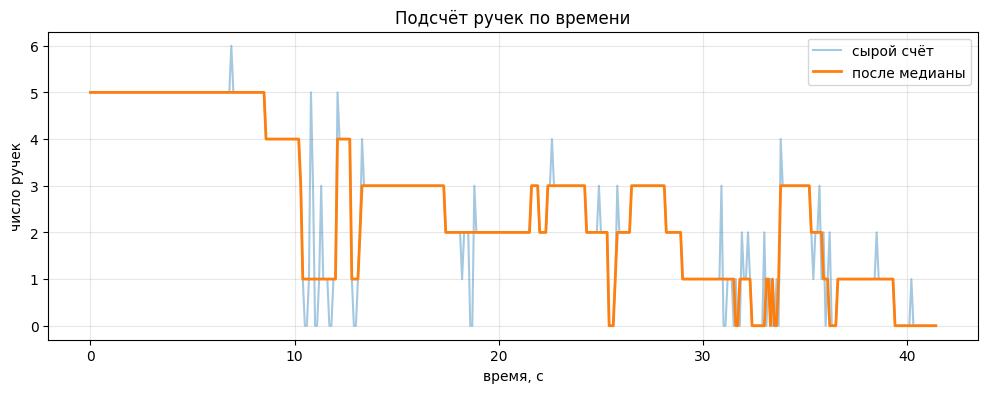

In [4]:
times, counts, t_proc = [], [], []
writer = None

for k, path in enumerate(files):
    frame = cv2.imread(path)
    t0 = time.time()
    n, out, _, _ = count_objects(frame)
    t_proc.append(time.time() - t0)
    times.append(k / FPS_OUT); counts.append(n)

    pair = np.hstack([frame, out])
    if writer is None:
        h, w = pair.shape[:2]
        writer = cv2.VideoWriter("/content/result_video1.mp4",
                                 cv2.VideoWriter_fourcc(*"mp4v"), FPS_OUT, (w, h))
    writer.write(pair)
writer.release()

times = np.array(times); counts = np.array(counts)
smooth = medfilt(counts, kernel_size=5)       # медиана по 5 отсчётам

print(f"Обработано кадров: {len(counts)} | время на кадр: {np.mean(t_proc)*1000:.1f} мс")

plt.figure(figsize=(12, 4))
plt.plot(times, counts, alpha=0.4, label="сырой счёт")
plt.plot(times, smooth, lw=2, label="после медианы")
plt.xlabel("время, с"); plt.ylabel("число ручек"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Подсчёт ручек по времени"); plt.show()

In [8]:

GT = [
    (0.0, 7.0, 5),     # все 5 на месте
    (9.0, 10.0, 4),    # зелёную убрали
    (14.0, 17.0, 3),   # синюю убрали
    (19.0, 21.0, 2),   # голубую убрали
    (23.0, 24.0, 3),   # зелёную положили обратно
    (27.0, 27.9, 3),
    (34.0, 35.5, 3),
    (37.5, 39.5, 1),   # осталась одна серая
    (41.0, 41.4, 0),   # стол пустой
]

def gt_at(t):
    for a, b, k in GT:
        if a <= t <= b:
            return k
    return None

rows = [(t, s, gt_at(t)) for t, s in zip(times, smooth) if gt_at(t) is not None]
pred = np.array([r[1] for r in rows]); true = np.array([r[2] for r in rows])

print(f"Оценённых кадров: {len(rows)}")
print(f"Точность подсчёта: {np.mean(pred == true) * 100:.1f}%")
print(f"Средняя ошибка (MAE): {np.mean(np.abs(pred - true)):.2f} ручки")
print(f"Время на кадр: {np.mean(t_proc)*1000:.1f} мс")

Оценённых кадров: 197
Точность подсчёта: 16.2%
Средняя ошибка (MAE): 2.72 ручки
Время на кадр: 154.0 мс


Второй тест при плохом освещении

In [6]:
import os
print(os.listdir("/content"))

['.config', 'IMG_0045.MOV', 'result_video1.mp4', 'WhatsApp Video 2026-10-12 at 1.05.06 AM.mp4', 'frames', 'result_video4_cross.mp4', 'WhatsApp Video 2026-10-11 at 11.10.06 PM.mp4', 'WhatsApp Video 2026-10-12 at 3.17.24 AM.mp4', 'frames_video4_cross', 'sample_data']


Кадров: 520 | размер файла, МБ: 6.32


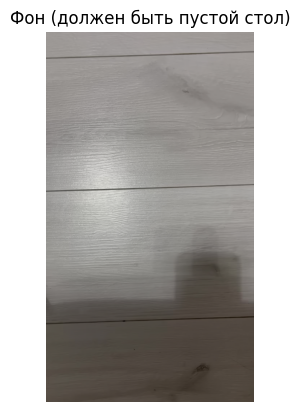

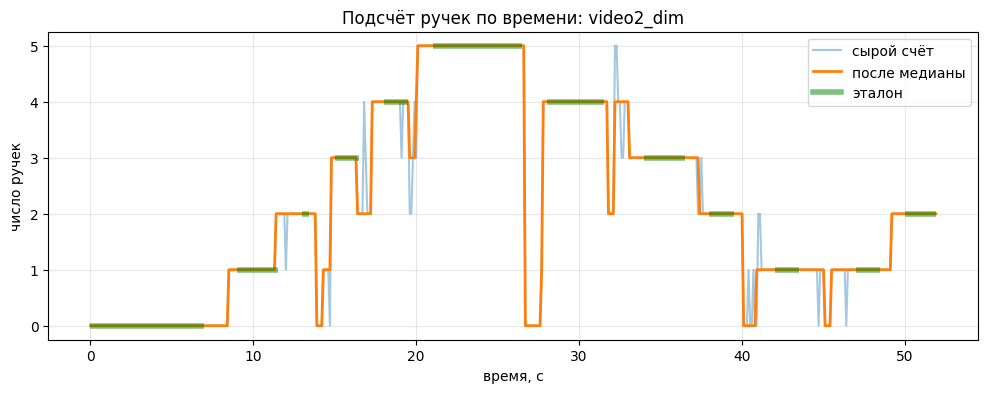

Оценённых кадров: 320
Точность подсчёта: 98.8%
Средняя ошибка (MAE): 0.01 ручки
Время на кадр: 154.0 мс
Ролик «до | после»: /content/result_video2_dim.mp4


In [7]:
import os, glob, subprocess, shutil, time
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import medfilt

VIDEO  = "/content/WhatsApp Video 2026-10-12 at 1.05.06 AM.mp4"   # имя скопируй из панели файлов Colab
NAME   = "video2_dim"                  # как назвать результат
BG_SEC = (1.0, 7.0)                    # секунды, где стол ПУСТОЙ и без руки (из них берётся фон)
DIFF_T = 22                            # порог разницы с фоном (в темноте можно 15-20)
GT = [                                 # (с секунды, по секунду, сколько ручек реально лежит)
    (0.0, 7.0, 0), (9.0, 11.5, 1), (13.0, 13.4, 2), (15.0, 16.5, 3),
    (18.0, 19.5, 4), (21.0, 26.5, 5), (28.0, 31.5, 4), (34.0, 36.5, 3),
    (38.0, 39.5, 2), (42.0, 43.5, 1), (47.0, 48.5, 1), (50.0, 51.9, 2),
]

FPS_OUT, BLUR = 10, (7, 7)
MIN_AREA, MIN_RATIO, MIN_FILL, BORDER = 300, 3.5, 0.6, 5

# 1. нарезка кадров через ffmpeg
frames_dir = f"/content/frames_{NAME}"
shutil.rmtree(frames_dir, ignore_errors=True); os.makedirs(frames_dir)
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", VIDEO, "-vf", f"fps={FPS_OUT}",
                "-q:v", "2", f"{frames_dir}/%04d.jpg"], check=True)
files = sorted(glob.glob(frames_dir + "/*.jpg"))
print("Кадров:", len(files), "| размер файла, МБ:", round(os.path.getsize(VIDEO) / 1e6, 2))

# 2. фон = медиана по нескольким кадрам пустого стола
a, b = int(BG_SEC[0] * FPS_OUT), min(int(BG_SEC[1] * FPS_OUT), len(files) - 1)
idx = np.unique(np.linspace(a, b, 12).astype(int))
bg = np.median(np.stack([cv2.imread(files[i]) for i in idx]), axis=0).astype(np.uint8)
H0, W0 = bg.shape[:2]
plt.imshow(cv2.cvtColor(bg, cv2.COLOR_BGR2RGB)); plt.title("Фон (должен быть пустой стол)")
plt.axis("off"); plt.show()

# 3. метод
sc = W0 / 576                                  # ядра подогнаны под ширину кадра 576 px
def odd(v): return max(3, int(round(v * sc)) // 2 * 2 + 1)
kernel_open  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (odd(5), odd(5)))
kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (odd(25), odd(9)))
kernel_blob  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (odd(61), odd(61)))   # шире ручки: рука, тень
kernel_grow  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (odd(15), odd(15)))

bg_f = cv2.GaussianBlur(bg, BLUR, 0).astype(np.float32)
bg_med = np.median(bg_f.reshape(-1, 3), axis=0)

def pen_color(h, s, v):                         # грубое имя цвета по HSV (в OpenCV H от 0 до 180)
    if s > 110:
        return "зелёная" if h < 95 else "синяя"
    if v < 80:
        return "серая"
    return "голубая" if h < 112 else "сиреневая"

LAST_PENS = []
def count_objects(frame):
    fb = cv2.GaussianBlur(frame, BLUR, 0).astype(np.float32)
    gain = np.median(fb.reshape(-1, 3), axis=0) / bg_med                  # выравнивание яркости
    diff = np.clip(np.abs(fb - bg_f * gain).max(axis=2), 0, 255).astype(np.uint8)
    mask = (diff > DIFF_T).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open)            # убрать шум
    big = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_blob)             # крупные пятна: рука, тень
    mask = cv2.bitwise_and(mask, cv2.bitwise_not(cv2.dilate(big, kernel_grow)))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel_close)          # склеить куски ручки

    H, W = mask.shape
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    out, count, pens = frame.copy(), 0, []
    for c in contours:
        if cv2.contourArea(c) < MIN_AREA:
            continue
        x, y, bw, bh = cv2.boundingRect(c)
        if x <= BORDER or y <= BORDER or x + bw >= W - BORDER or y + bh >= H - BORDER:
            continue
        (cx, cy), (w, h), ang = cv2.minAreaRect(c)
        ratio = max(w, h) / max(min(w, h), 1)
        fill = cv2.contourArea(cv2.convexHull(c)) / max(w * h, 1)
        if ratio < MIN_RATIO or fill < MIN_FILL:
            continue
        count += 1
        cv2.drawContours(out, [cv2.boxPoints(((cx, cy), (w, h), ang)).astype(int)], 0, (0, 255, 0), 2)
        # цвет: медиана HSV внутри контура (чуть уменьшенного, чтобы не брать края)
        inside = np.zeros(mask.shape, np.uint8); cv2.drawContours(inside, [c], -1, 255, -1)
        inside = cv2.erode(inside, np.ones((5, 5), np.uint8))
        hh, ss, vv = [float(np.median(hsv[..., i][inside > 0])) for i in range(3)]
        angle = ang if w >= h else ang + 90                               # угол длинной оси к горизонтали
        pens.append(dict(x=cx, y=cy, length=max(w, h), width=min(w, h),
                         angle=(angle + 90) % 180 - 90, color=pen_color(hh, ss, vv)))
    cv2.putText(out, f"Ruchek: {count}", (10, 35), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
    global LAST_PENS
    LAST_PENS = sorted(pens, key=lambda p: p["y"])                        # сверху вниз
    return count, out, diff, mask

# 4. весь ролик: «до | после»
times, counts, t_proc = [], [], []
writer = None
result_path = f"/content/result_{NAME}.mp4"
for k, path in enumerate(files):
    frame = cv2.imread(path)
    t0 = time.time()
    n, out, _, _ = count_objects(frame)
    t_proc.append(time.time() - t0)
    times.append(k / FPS_OUT); counts.append(n)
    pair = np.hstack([frame, out])
    if writer is None:
        writer = cv2.VideoWriter(result_path, cv2.VideoWriter_fourcc(*"mp4v"), FPS_OUT, (pair.shape[1], pair.shape[0]))
    writer.write(pair)
writer.release()
times, counts = np.array(times), np.array(counts)
smooth = medfilt(counts, kernel_size=5)

# 5. график
plt.figure(figsize=(12, 4))
plt.plot(times, counts, alpha=0.4, label="сырой счёт")
plt.plot(times, smooth, lw=2, label="после медианы")
for a_, b_, k_ in GT:
    plt.hlines(k_, a_, b_, colors="green", lw=4, alpha=0.5)
plt.plot([], [], color="green", lw=4, alpha=0.5, label="эталон")
plt.xlabel("время, с"); plt.ylabel("число ручек"); plt.legend(); plt.grid(alpha=0.3)
plt.title(f"Подсчёт ручек по времени: {NAME}"); plt.show()

# 6. точность
def gt_at(t):
    for a_, b_, k_ in GT:
        if a_ <= t <= b_:
            return k_
rows = [(s, gt_at(t)) for t, s in zip(times, smooth) if gt_at(t) is not None]
pred = np.array([r[0] for r in rows]); true = np.array([r[1] for r in rows])
print(f"Оценённых кадров: {len(rows)}")
print(f"Точность подсчёта: {np.mean(pred == true) * 100:.1f}%")
print(f"Средняя ошибка (MAE): {np.mean(np.abs(pred - true)):.2f} ручки")
print(f"Время на кадр: {np.mean(t_proc) * 1000:.1f} мс")
print("Ролик «до | после»:", result_path)

In [9]:
VIDEO  = "/content/WhatsApp Video 2026-10-11 at 11.10.06 PM.mp4"
NAME   = "video1_normal"
BG_SEC = (41.0, 41.4)
GT = [(0.0,7.0,5),(9.0,10.0,4),(14.0,17.0,3),(19.0,21.0,2),(23.0,24.0,3),(27.0,27.9,3),(34.0,35.5,3),(37.5,39.5,1),(41.0,41.4,0)]

3 тест ручки крест на крест

Кадров: 340 | размер файла, МБ: 5.89


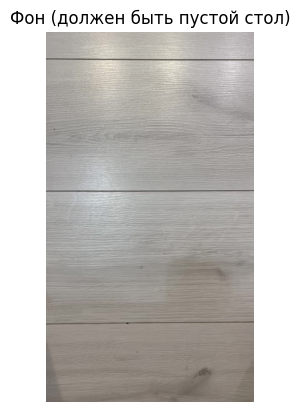

Площадь одной ручки (оценка по ролику): 8162 px, объектов в выборке: 42


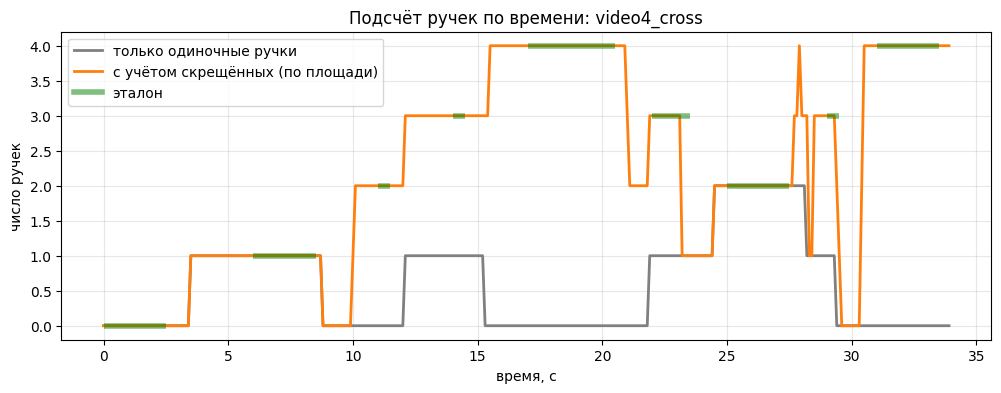

Оценённых кадров: 174
Только одиночные ручки:   точность 44.8%,  MAE 1.83
С учётом скрещённых:      точность 96.6%,  MAE 0.06
Время на кадр: 169.3 мс
Ролик «до | после»: /content/result_video4_cross.mp4


In [10]:
import os, glob, subprocess, shutil, time
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import medfilt

# ================== НАСТРОЙКИ (меняешь только это) ==================
VIDEO   = "/content/WhatsApp Video 2026-10-12 at 3.17.24 AM.mp4"   # имя скопируй из панели файлов Colab
NAME    = "video4_cross"
BG_SEC  = (0.5, 2.5)          # секунды, где стол ПУСТОЙ и без руки (из них берётся фон)
CLUSTER = True                # считать ли скрещённые/слипшиеся ручки по площади
DIFF_T  = 22                  # порог разницы с фоном
GT = [                        # (с секунды, по секунду, сколько ручек реально лежит)
    (0.0, 2.5, 0), (6.0, 8.5, 1), (11.0, 11.5, 2), (14.0, 14.5, 3), (17.0, 20.5, 4),
    (22.0, 23.5, 3), (25.0, 27.5, 2), (29.0, 29.5, 3), (31.0, 33.5, 4),
]
# =====================================================================

FPS_OUT, BLUR = 10, (7, 7)
MIN_AREA, MIN_RATIO, MIN_FILL, BORDER = 300, 3.5, 0.6, 5
CLUSTER_K = 1.4               # объект крупнее 1.4 площади одной ручки считаем группой

# 1. нарезка кадров через ffmpeg
frames_dir = f"/content/frames_{NAME}"
shutil.rmtree(frames_dir, ignore_errors=True); os.makedirs(frames_dir)
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", VIDEO, "-vf", f"fps={FPS_OUT}",
                "-q:v", "2", f"{frames_dir}/%04d.jpg"], check=True)
files = sorted(glob.glob(frames_dir + "/*.jpg"))
print("Кадров:", len(files), "| размер файла, МБ:", round(os.path.getsize(VIDEO) / 1e6, 2))

# 2. фон = медиана по нескольким кадрам пустого стола
a, b = int(BG_SEC[0] * FPS_OUT), min(int(BG_SEC[1] * FPS_OUT), len(files) - 1)
idx = np.unique(np.linspace(a, b, 12).astype(int))
bg = np.median(np.stack([cv2.imread(files[i]) for i in idx]), axis=0).astype(np.uint8)
H0, W0 = bg.shape[:2]
plt.imshow(cv2.cvtColor(bg, cv2.COLOR_BGR2RGB)); plt.title("Фон (должен быть пустой стол)")
plt.axis("off"); plt.show()

# 3. метод
sc = W0 / 576                                  # ядра подогнаны под ширину кадра 576 px
def odd(v): return max(3, int(round(v * sc)) // 2 * 2 + 1)
kernel_open  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (odd(5), odd(5)))
kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (odd(25), odd(9)))
kernel_blob  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (odd(61), odd(61)))   # шире ручки: рука, тень
kernel_grow  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (odd(15), odd(15)))

bg_f = cv2.GaussianBlur(bg, BLUR, 0).astype(np.float32)
bg_med = np.median(bg_f.reshape(-1, 3), axis=0)

def pen_color(h, s, v):                         # грубое имя цвета по HSV (в OpenCV H от 0 до 180)
    if s > 110:
        return "зелёная" if h < 95 else "синяя"
    if v < 80:
        return "серая"
    return "голубая" if h < 112 else "сиреневая"

def make_mask(frame):
    fb = cv2.GaussianBlur(frame, BLUR, 0).astype(np.float32)
    gain = np.median(fb.reshape(-1, 3), axis=0) / bg_med                  # выравнивание яркости
    diff = np.clip(np.abs(fb - bg_f * gain).max(axis=2), 0, 255).astype(np.uint8)
    mask = (diff > DIFF_T).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open)            # убрать шум
    big = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_blob)             # крупные пятна: рука, тень
    mask = cv2.bitwise_and(mask, cv2.bitwise_not(cv2.dilate(big, kernel_grow)))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel_close)          # склеить куски ручки
    return diff, mask

# «размер одной ручки» = медиана площади объектов, похожих на одиночную ручку, по всему ролику
_areas = []
for i in range(0, len(files), 5):
    H_, W_ = bg.shape[:2]
    cs, _ = cv2.findContours(make_mask(cv2.imread(files[i]))[1], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for c in cs:
        A_ = cv2.contourArea(c)
        x_, y_, bw_, bh_ = cv2.boundingRect(c)
        if A_ < MIN_AREA or x_ <= BORDER or y_ <= BORDER or x_ + bw_ >= W_ - BORDER or y_ + bh_ >= H_ - BORDER:
            continue
        (_, _), (w_, h_), _ = cv2.minAreaRect(c)
        if max(w_, h_) / max(min(w_, h_), 1) >= MIN_RATIO and A_ / max(w_ * h_, 1) >= MIN_FILL:
            _areas.append(A_)
A_REF = float(np.median(_areas))
print(f"Площадь одной ручки (оценка по ролику): {A_REF:.0f} px, объектов в выборке: {len(_areas)}")

LAST_PENS, LAST_BASE = [], 0
def count_objects(frame):
    diff, mask = make_mask(frame)
    H, W = mask.shape
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    out, n_single, n_group, pens = frame.copy(), 0, 0, []
    for c in contours:
        area = cv2.contourArea(c)
        if area < MIN_AREA:
            continue
        x, y, bw, bh = cv2.boundingRect(c)
        if x <= BORDER or y <= BORDER or x + bw >= W - BORDER or y + bh >= H - BORDER:
            continue
        (cx, cy), (w, h), ang = cv2.minAreaRect(c)
        ratio = max(w, h) / max(min(w, h), 1)
        fill = cv2.contourArea(cv2.convexHull(c)) / max(w * h, 1)
        box = cv2.boxPoints(((cx, cy), (w, h), ang)).astype(int)
        if ratio >= MIN_RATIO and fill >= MIN_FILL:                       # одиночная ручка
            n_single += 1
            cv2.drawContours(out, [box], 0, (0, 255, 0), 2)
            inside = np.zeros(mask.shape, np.uint8); cv2.drawContours(inside, [c], -1, 255, -1)
            inside = cv2.erode(inside, np.ones((5, 5), np.uint8))
            hh, ss, vv = [float(np.median(hsv[..., i][inside > 0])) for i in range(3)]
            angle = ang if w >= h else ang + 90
            pens.append(dict(x=cx, y=cy, length=max(w, h), width=min(w, h),
                             angle=(angle + 90) % 180 - 90, color=pen_color(hh, ss, vv)))
        elif CLUSTER and area >= CLUSTER_K * A_REF:                       # скрещённые/слипшиеся ручки
            k = max(1, int(round(area / A_REF)))
            n_group += k
            cv2.drawContours(out, [c], -1, (0, 165, 255), 2)
            cv2.putText(out, f"x{k}", (int(cx), int(cy)), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 165, 255), 3)
            pens.append(dict(x=cx, y=cy, length=max(w, h), width=min(w, h), angle=0.0, color=f"группа x{k}"))
    total = n_single + n_group
    cv2.putText(out, f"Ruchek: {total}", (10, 35), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
    global LAST_PENS, LAST_BASE
    LAST_PENS = sorted(pens, key=lambda p: p["y"])
    LAST_BASE = n_single                                                  # счёт без учёта групп
    return total, out, diff, mask

# 4. весь ролик: «до | после»
times, counts, counts_base, t_proc = [], [], [], []
writer = None
result_path = f"/content/result_{NAME}.mp4"
for k, path in enumerate(files):
    frame = cv2.imread(path)
    t0 = time.time()
    n, out, _, _ = count_objects(frame)
    t_proc.append(time.time() - t0)
    times.append(k / FPS_OUT); counts.append(n); counts_base.append(LAST_BASE)
    pair = np.hstack([frame, out])
    if writer is None:
        writer = cv2.VideoWriter(result_path, cv2.VideoWriter_fourcc(*"mp4v"), FPS_OUT, (pair.shape[1], pair.shape[0]))
    writer.write(pair)
writer.release()
times, counts, counts_base = np.array(times), np.array(counts), np.array(counts_base)
smooth, smooth_base = medfilt(counts, 5), medfilt(counts_base, 5)

# 5. график
plt.figure(figsize=(12, 4))
plt.plot(times, smooth_base, lw=2, color="gray", label="только одиночные ручки")
plt.plot(times, smooth, lw=2, color="C1", label="с учётом скрещённых (по площади)")
for a_, b_, k_ in GT:
    plt.hlines(k_, a_, b_, colors="green", lw=4, alpha=0.5)
plt.plot([], [], color="green", lw=4, alpha=0.5, label="эталон")
plt.xlabel("время, с"); plt.ylabel("число ручек"); plt.legend(); plt.grid(alpha=0.3)
plt.title(f"Подсчёт ручек по времени: {NAME}"); plt.show()

# 6. точность
def gt_at(t):
    for a_, b_, k_ in GT:
        if a_ <= t <= b_:
            return k_
def evaluate(sm):
    rows = [(s, gt_at(t)) for t, s in zip(times, sm) if gt_at(t) is not None]
    p = np.array([r[0] for r in rows]); g = np.array([r[1] for r in rows])
    return len(rows), np.mean(p == g) * 100, np.mean(np.abs(p - g))
n1, acc1, mae1 = evaluate(smooth_base)
n2, acc2, mae2 = evaluate(smooth)
print(f"Оценённых кадров: {n2}")
print(f"Только одиночные ручки:   точность {acc1:.1f}%,  MAE {mae1:.2f}")
print(f"С учётом скрещённых:      точность {acc2:.1f}%,  MAE {mae2:.2f}")
print(f"Время на кадр: {np.mean(t_proc) * 1000:.1f} мс")
print("Ролик «до | после»:", result_path)

4 видео с шахматной доской

Кадров из видео: 127 | размер файла, МБ: 108.0
Доска найдена на 98 из 127 кадров, размер кадра (1920, 1078)
итерация 0: кадров 49, RMS 1.200 px, макс. ошибка кадра 587.21 px

=== РЕЗУЛЬТАТ КАЛИБРОВКИ ===
Матрица камеры K:
 [[1.6612e+03 0.0000e+00 9.4360e+02]
 [0.0000e+00 1.6518e+03 5.9230e+02]
 [0.0000e+00 0.0000e+00 1.0000e+00]]
Коэффициенты дисторсии (k1, k2, p1, p2, k3): [ 0.1164 -0.2677  0.0087 -0.0114  0.    ]
Ошибка перепроекции (RMS): 1.200 px по 49 кадрам
Ошибка на кадрах вне калибровки (49 шт.): 435.138 px


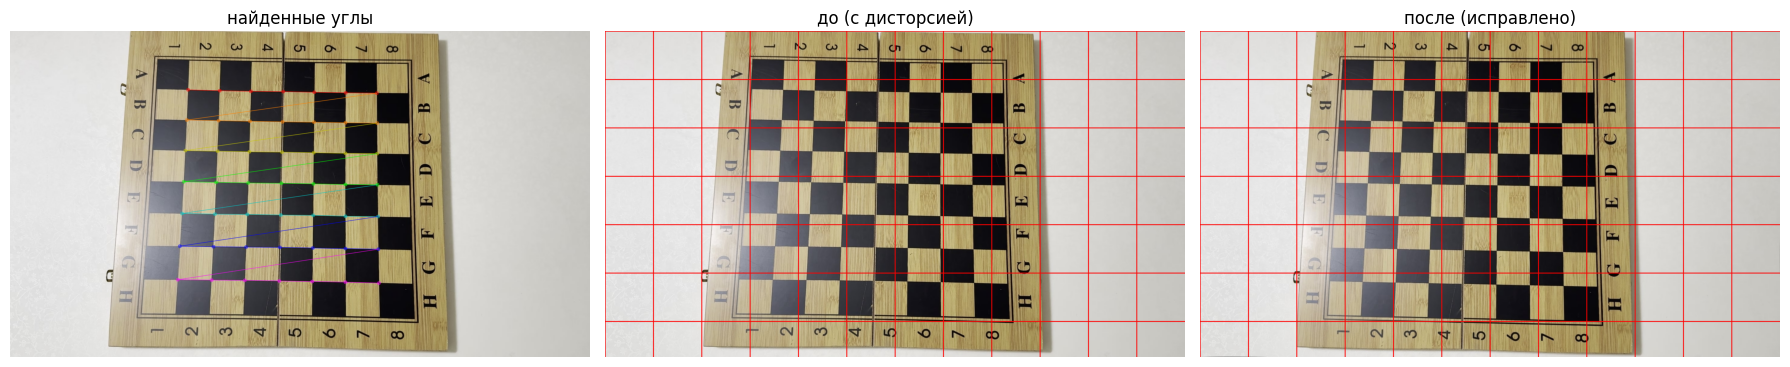

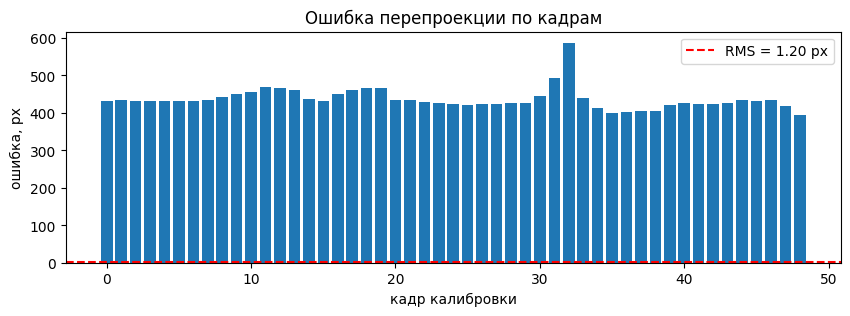

In [11]:
import os, glob, subprocess, shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ================== НАСТРОЙКИ ==================
VIDEO   = "/content/IMG_0045.MOV"   # видео шахматной доски (имя скопируй из панели файлов Colab)
PATTERN = (7, 7)                    # ВНУТРЕННИЕ углы доски: у доски 8x8 клеток это 7x7
SQUARE  = 1.0                       # сторона клетки (если измеришь в мм, впиши сюда; иначе единицы = клетки)
FPS_CB  = 2                         # сколько кадров в секунду берём из видео
# ===============================================

# 1. кадры из видео
frames_dir = "/content/frames_board"
shutil.rmtree(frames_dir, ignore_errors=True); os.makedirs(frames_dir)
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", VIDEO, "-vf", f"fps={FPS_CB}",
                "-q:v", "2", f"{frames_dir}/%04d.jpg"], check=True)
files = sorted(glob.glob(frames_dir + "/*.jpg"))
print("Кадров из видео:", len(files), "| размер файла, МБ:", round(os.path.getsize(VIDEO) / 1e6, 1))

# 2. поиск углов доски (грубо на уменьшенном кадре, потом уточняем на полном)
objp = np.zeros((PATTERN[0] * PATTERN[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:PATTERN[0], 0:PATTERN[1]].T.reshape(-1, 2) * SQUARE
crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 40, 0.001)
flags_find = cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE + cv2.CALIB_CB_FAST_CHECK
objpts, imgpts, used = [], [], []
for i, path in enumerate(files):
    gray = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2GRAY)
    small = cv2.resize(gray, None, fx=0.5, fy=0.5)
    ok, corners = cv2.findChessboardCorners(small, PATTERN, flags_find)
    if not ok:
        continue
    corners = cv2.cornerSubPix(gray, corners * 2, (11, 11), (-1, -1), crit)   # уточнение до долей пикселя
    objpts.append(objp); imgpts.append(corners); used.append(i)
size = (gray.shape[1], gray.shape[0])
print(f"Доска найдена на {len(used)} из {len(files)} кадров, размер кадра {size}")

# 3. калибровка + отбрасывание плохих кадров
def calibrate(idx):
    o = [objpts[i] for i in idx]; m = [imgpts[i] for i in idx]
    rms, K, D, rv, tv = cv2.calibrateCamera(o, m, size, None, None, flags=cv2.CALIB_FIX_K3)
    errs = [np.sqrt(np.mean(np.sum((mm - cv2.projectPoints(oo, r, t, K, D)[0]) ** 2, axis=2)))
            for oo, mm, r, t in zip(o, m, rv, tv)]
    return rms, K, D, np.array(errs)

sel = list(range(0, len(used), 2))            # каждый 2-й найденный кадр
for it in range(6):
    rms, K, D, errs = calibrate(sel)
    print(f"итерация {it}: кадров {len(sel)}, RMS {rms:.3f} px, макс. ошибка кадра {errs.max():.2f} px")
    keep = [s for s, e in zip(sel, errs) if e <= max(1.5 * np.median(errs), 0.5)]   # выбросы убираем
    if len(keep) == len(sel):
        break
    sel = keep

print("\n=== РЕЗУЛЬТАТ КАЛИБРОВКИ ===")
print("Матрица камеры K:\n", np.round(K, 1))
print("Коэффициенты дисторсии (k1, k2, p1, p2, k3):", np.round(D.ravel(), 4))
print(f"Ошибка перепроекции (RMS): {rms:.3f} px по {len(sel)} кадрам")
np.savez("/content/calibration.npz", K=K, D=D, size=size, rms=rms)

# 4. проверка на кадрах, которые в калибровку не входили
rest = [i for i in range(len(used)) if i not in sel]
e_rest = []
for i in rest:
    _, r, t = cv2.solvePnP(objpts[i], imgpts[i], K, D)
    pr, _ = cv2.projectPoints(objpts[i], r, t, K, D)
    e_rest.append(np.sqrt(np.mean(np.sum((imgpts[i] - pr) ** 2, axis=2))))
print(f"Ошибка на кадрах вне калибровки ({len(rest)} шт.): {np.mean(e_rest):.3f} px")

# 5. картинки: найденные углы и «до / после» исправления дисторсии
k0 = used[sel[len(sel) // 2]]
img = cv2.imread(files[k0]); h, w = img.shape[:2]
shown = cv2.drawChessboardCorners(img.copy(), PATTERN, imgpts[sel[len(sel) // 2]], True)
newK, _ = cv2.getOptimalNewCameraMatrix(K, D, (w, h), 0)
und = cv2.undistort(img, K, D, None, newK)
def grid(im):
    o = im.copy()
    for x in range(0, w, 160): cv2.line(o, (x, 0), (x, h), (0, 0, 255), 2)
    for y in range(0, h, 160): cv2.line(o, (0, y), (w, y), (0, 0, 255), 2)
    return o
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, im, t in zip(ax, [shown, grid(img), grid(und)], ["найденные углы", "до (с дисторсией)", "после (исправлено)"]):
    a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 3))
plt.bar(range(len(errs)), errs); plt.axhline(rms, color="r", ls="--", label=f"RMS = {rms:.2f} px")
plt.xlabel("кадр калибровки"); plt.ylabel("ошибка, px"); plt.legend(); plt.title("Ошибка перепроекции по кадрам")
plt.show()

Более понятная версия с комментариями. Ячейка 1. Подсчёт ручек

In [ ]:
# =====================================================================
# ЯЧЕЙКА 1. Подсчёт ручек на видео, положение и цвет каждой ручки.
# Идея: каждый кадр сравниваем с «пустым столом» (фоном). Всё, что от
# фона отличается, считаем предметами, а затем отбираем по форме:
# ручка вытянутая, рука и тень нет.
# =====================================================================
import os, glob, subprocess, shutil, time   # файлы, запуск ffmpeg, замер времени
import cv2                                    # OpenCV: обработка изображений
import numpy as np                            # массивы и математика
import matplotlib.pyplot as plt               # графики и картинки
from scipy.signal import medfilt              # медианный фильтр (сглаживание счёта по времени)

# ================== НАСТРОЙКИ (меняешь только это) ==================
VIDEO   = "/content/WhatsApp Video 2026-10-12 at 3.17.24 AM.mp4"   # путь к видео (имя смотри в панели файлов Colab)
NAME    = "video4_cross"      # имя ролика: от него зависят названия папок и результата
BG_SEC  = (0.5, 2.5)          # секунды, где стол ПУСТОЙ и без руки (из них строится фон)
CLUSTER = True                # True: считать скрещённые/слипшиеся ручки по площади; False: только одиночные
DIFF_T  = 22                  # порог разницы с фоном (0-255); меньше = чувствительнее к бледным ручкам
GT = [                        # эталон: (с секунды, по секунду, сколько ручек реально лежит)
    (0.0, 2.5, 0), (6.0, 8.5, 1), (11.0, 11.5, 2), (14.0, 14.5, 3), (17.0, 20.5, 4),
    (22.0, 23.5, 3), (25.0, 27.5, 2), (29.0, 29.5, 3), (31.0, 33.5, 4),
]
# =====================================================================

FPS_OUT, BLUR = 10, (7, 7)    # берём 10 кадров в секунду; BLUR — размер ядра размытия по Гауссу
MIN_AREA = 300                # объекты с площадью меньше (в пикселях) считаем шумом
MIN_RATIO = 3.5               # ручка вытянутая: длина / ширина не меньше 3,5
MIN_FILL = 0.6                # насколько контур заполняет свой прямоугольник (отсекает рваные пятна)
BORDER = 5                    # объекты, касающиеся края кадра (рука, шов стола), не считаем
CLUSTER_K = 1.4               # пятно крупнее 1,4 площади одной ручки считаем группой ручек

# ---------- 1. Нарезка видео на кадры ----------
# ffmpeg надёжнее читает видео с телефона, чем cv2.VideoCapture (в Colab тот отдавал битые кадры)
frames_dir = f"/content/frames_{NAME}"
shutil.rmtree(frames_dir, ignore_errors=True); os.makedirs(frames_dir)   # чистая папка для кадров
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", VIDEO, "-vf", f"fps={FPS_OUT}",
                "-q:v", "2", f"{frames_dir}/%04d.jpg"], check=True)     # check=True: при ошибке ffmpeg код остановится
files = sorted(glob.glob(frames_dir + "/*.jpg"))                         # список кадров по порядку
print("Кадров:", len(files), "| размер файла, МБ:", round(os.path.getsize(VIDEO) / 1e6, 2))

# ---------- 2. Фон ----------
# Фон = медиана 12 кадров пустого стола: случайные помехи (шум, мелькнувшая тень) в медиану не попадают
a, b = int(BG_SEC[0] * FPS_OUT), min(int(BG_SEC[1] * FPS_OUT), len(files) - 1)   # номера кадров из секунд
idx = np.unique(np.linspace(a, b, 12).astype(int))                                # 12 кадров равномерно
bg = np.median(np.stack([cv2.imread(files[i]) for i in idx]), axis=0).astype(np.uint8)
H0, W0 = bg.shape[:2]                                                             # высота и ширина кадра
plt.imshow(cv2.cvtColor(bg, cv2.COLOR_BGR2RGB)); plt.title("Фон (должен быть пустой стол)")
plt.axis("off"); plt.show()                                                       # проверь глазами: рук и предметов нет

# ---------- 3. Метод ----------
# Размеры ядер подобраны под ширину кадра 576 px; для другого разрешения масштабируем
sc = W0 / 576
def odd(v): return max(3, int(round(v * sc)) // 2 * 2 + 1)   # масштабируем размер и делаем его нечётным
kernel_open  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (odd(5), odd(5)))     # убирает мелкий шум
kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (odd(25), odd(9)))       # вытянутое: склеивает куски ручки по длине
kernel_blob  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (odd(61), odd(61)))   # шире ручки: «ловит» руку и тень
kernel_grow  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (odd(15), odd(15)))   # расширяет найденные пятна руки

bg_f = cv2.GaussianBlur(bg, BLUR, 0).astype(np.float32)   # размытый фон (float, чтобы вычитать без переполнения)
bg_med = np.median(bg_f.reshape(-1, 3), axis=0)           # типичная яркость фона по каналам B, G, R

def pen_color(h, s, v):
    """Грубое имя цвета по HSV (в OpenCV оттенок H от 0 до 180)."""
    if s > 110:                                  # насыщенный цвет: зелёная или синяя
        return "зелёная" if h < 95 else "синяя"
    if v < 80:                                   # тёмная и бесцветная
        return "серая"
    return "голубая" if h < 112 else "сиреневая" # светлые: различаем по оттенку

def make_mask(frame):
    """Возвращает (разница с фоном, чистая маска «где что-то лежит»)."""
    fb = cv2.GaussianBlur(frame, BLUR, 0).astype(np.float32)           # размываем кадр: подавляем шум
    gain = np.median(fb.reshape(-1, 3), axis=0) / bg_med               # во сколько раз кадр ярче/темнее фона (автоэкспозиция телефона)
    diff = np.clip(np.abs(fb - bg_f * gain).max(axis=2), 0, 255).astype(np.uint8)  # разница с фоном с учётом яркости
    mask = (diff > DIFF_T).astype(np.uint8) * 255                      # порог: белое = отличается от фона
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open)         # открытие: убираем мелкий шум
    big = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_blob)          # остаются только пятна шире ручки: рука, тень
    mask = cv2.bitwise_and(mask, cv2.bitwise_not(cv2.dilate(big, kernel_grow)))   # вырезаем их из маски
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open)         # убираем остатки после вырезания
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel_close)       # закрытие: склеиваем куски бледной ручки
    return diff, mask

# Размер одной ручки: медиана площади объектов, похожих на одиночную ручку, по всему ролику.
# Он нужен, чтобы оценить, сколько ручек в слипшемся пятне (площадь пятна / площадь одной).
_areas = []
for i in range(0, len(files), 5):                                      # каждый 5-й кадр, чтобы было быстро
    H_, W_ = bg.shape[:2]
    cs, _ = cv2.findContours(make_mask(cv2.imread(files[i]))[1], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for c in cs:
        A_ = cv2.contourArea(c)
        x_, y_, bw_, bh_ = cv2.boundingRect(c)
        if A_ < MIN_AREA or x_ <= BORDER or y_ <= BORDER or x_ + bw_ >= W_ - BORDER or y_ + bh_ >= H_ - BORDER:
            continue                                                   # шум и объекты у края пропускаем
        (_, _), (w_, h_), _ = cv2.minAreaRect(c)                       # повёрнутый прямоугольник вокруг контура
        if max(w_, h_) / max(min(w_, h_), 1) >= MIN_RATIO and A_ / max(w_ * h_, 1) >= MIN_FILL:
            _areas.append(A_)                                          # похоже на одиночную ручку: запоминаем площадь
A_REF = float(np.median(_areas))
print(f"Площадь одной ручки (оценка по ролику): {A_REF:.0f} px, объектов в выборке: {len(_areas)}")

LAST_PENS, LAST_BASE = [], 0       # результаты последнего кадра (читаются в других ячейках)
def count_objects(frame):
    """Считает ручки на кадре. Возвращает (число ручек, кадр с рамками, разница, маска)."""
    diff, mask = make_mask(frame)
    H, W = mask.shape
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)   # контуры белых пятен
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)                       # HSV нужен для определения цвета
    out, n_single, n_group, pens = frame.copy(), 0, 0, []
    for c in contours:
        area = cv2.contourArea(c)
        if area < MIN_AREA:
            continue                                                   # слишком мелкое: шум
        x, y, bw, bh = cv2.boundingRect(c)
        if x <= BORDER or y <= BORDER or x + bw >= W - BORDER or y + bh >= H - BORDER:
            continue                                                   # касается края кадра: рука или шов, не ручка
        (cx, cy), (w, h), ang = cv2.minAreaRect(c)                     # центр, размеры и угол повёрнутого прямоугольника
        ratio = max(w, h) / max(min(w, h), 1)                          # вытянутость
        fill = cv2.contourArea(cv2.convexHull(c)) / max(w * h, 1)      # заполненность (по выпуклой оболочке, дырки не мешают)
        box = cv2.boxPoints(((cx, cy), (w, h), ang)).astype(int)       # углы прямоугольника для рисования
        if ratio >= MIN_RATIO and fill >= MIN_FILL:                    # --- одиночная ручка ---
            n_single += 1
            cv2.drawContours(out, [box], 0, (0, 255, 0), 2)            # зелёная рамка
            inside = np.zeros(mask.shape, np.uint8); cv2.drawContours(inside, [c], -1, 255, -1)  # заливаем контур
            inside = cv2.erode(inside, np.ones((5, 5), np.uint8))      # чуть сужаем, чтобы не брать краевые пиксели
            hh, ss, vv = [float(np.median(hsv[..., i][inside > 0])) for i in range(3)]   # медианный цвет внутри ручки
            angle = ang if w >= h else ang + 90                        # угол именно длинной стороны
            pens.append(dict(x=cx, y=cy, length=max(w, h), width=min(w, h),
                             angle=(angle + 90) % 180 - 90, color=pen_color(hh, ss, vv)))
        elif CLUSTER and area >= CLUSTER_K * A_REF:                    # --- скрещённые/слипшиеся ручки ---
            k = max(1, int(round(area / A_REF)))                       # сколько ручек: площадь пятна / площадь одной
            n_group += k
            cv2.drawContours(out, [c], -1, (0, 165, 255), 2)           # оранжевый контур группы
            cv2.putText(out, f"x{k}", (int(cx), int(cy)), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 165, 255), 3)
            pens.append(dict(x=cx, y=cy, length=max(w, h), width=min(w, h), angle=0.0, color=f"группа x{k}"))
    total = n_single + n_group
    cv2.putText(out, f"Ruchek: {total}", (10, 35), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)  # (латиница: cv2 не рисует кириллицу)
    global LAST_PENS, LAST_BASE
    LAST_PENS = sorted(pens, key=lambda p: p["y"])                     # ручки сверху вниз
    LAST_BASE = n_single                                               # счёт без учёта групп (для сравнения на графике)
    return total, out, diff, mask

# ---------- 4. Весь ролик: счёт на каждом кадре и видео «до | после» ----------
times, counts, counts_base, t_proc = [], [], [], []
writer = None
result_path = f"/content/result_{NAME}.mp4"
for k, path in enumerate(files):
    frame = cv2.imread(path)
    t0 = time.time()
    n, out, _, _ = count_objects(frame)
    t_proc.append(time.time() - t0)                                    # сколько ушло на этот кадр
    times.append(k / FPS_OUT); counts.append(n); counts_base.append(LAST_BASE)
    pair = np.hstack([frame, out])                                     # слева исходный кадр, справа результат
    if writer is None:                                                 # создаём видеофайл при первом кадре
        writer = cv2.VideoWriter(result_path, cv2.VideoWriter_fourcc(*"mp4v"), FPS_OUT, (pair.shape[1], pair.shape[0]))
    writer.write(pair)
writer.release()
times, counts, counts_base = np.array(times), np.array(counts), np.array(counts_base)
smooth, smooth_base = medfilt(counts, 5), medfilt(counts_base, 5)      # медиана по 5 отсчётам убирает одиночные скачки

# ---------- 5. График счёта по времени ----------
plt.figure(figsize=(12, 4))
plt.plot(times, smooth_base, lw=2, color="gray", label="только одиночные ручки")
plt.plot(times, smooth, lw=2, color="C1", label="с учётом скрещённых (по площади)")
for a_, b_, k_ in GT:
    plt.hlines(k_, a_, b_, colors="green", lw=4, alpha=0.5)            # зелёные отрезки = эталон
plt.plot([], [], color="green", lw=4, alpha=0.5, label="эталон")       # пустая линия только для легенды
plt.xlabel("время, с"); plt.ylabel("число ручек"); plt.legend(); plt.grid(alpha=0.3)
plt.title(f"Подсчёт ручек по времени: {NAME}"); plt.show()

# ---------- 6. Точность относительно эталона ----------
def gt_at(t):
    """Эталонное число ручек в момент t (None, если момент не размечен)."""
    for a_, b_, k_ in GT:
        if a_ <= t <= b_:
            return k_
def evaluate(sm):
    """Возвращает (число оценённых кадров, точность %, средняя ошибка)."""
    rows = [(s, gt_at(t)) for t, s in zip(times, sm) if gt_at(t) is not None]
    p = np.array([r[0] for r in rows]); g = np.array([r[1] for r in rows])
    return len(rows), np.mean(p == g) * 100, np.mean(np.abs(p - g))
n1, acc1, mae1 = evaluate(smooth_base)
n2, acc2, mae2 = evaluate(smooth)
print(f"Оценённых кадров: {n2}")
print(f"Только одиночные ручки:   точность {acc1:.1f}%,  MAE {mae1:.2f}")
print(f"С учётом скрещённых:      точность {acc2:.1f}%,  MAE {mae2:.2f}")
print(f"Время на кадр: {np.mean(t_proc) * 1000:.1f} мс")
print("Ролик «до | после»:", result_path)

Ячейка 2. Положение и цвет ручек (запускай после ячейки 1)

In [ ]:
# =====================================================================
# ЯЧЕЙКА 2. Разбор положения ручек на выбранных кадрах.
# Запускается ПОСЛЕ ячейки 1 (использует её переменные и функции).
# Для каждой ручки выводит цвет, центр, угол, длину и толщину.
# =====================================================================
SECONDS = [11, 19, 32]          # какие моменты видео разобрать (секунды); подбери под свой ролик
SECONDS = [s for s in SECONDS if int(s * FPS_OUT) < len(files)]   # секунды за пределами видео пропускаем

fig, axes = plt.subplots(1, len(SECONDS), figsize=(5 * len(SECONDS), 8))
for ax, sec in zip(np.atleast_1d(axes), SECONDS):
    f = cv2.imread(files[int(sec * FPS_OUT)])        # кадр на нужной секунде
    n, out, _, _ = count_objects(f)                  # после вызова LAST_PENS хранит данные по ручкам этого кадра
    ax.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))  # cv2 хранит цвета как BGR, matplotlib ждёт RGB
    print(f"\n{sec} с: найдено {n}")
    for i, p in enumerate(LAST_PENS, 1):             # ручки отсортированы сверху вниз
        ax.text(p["x"], p["y"] - 40, f"{i}: {p['color']}", color="yellow", fontsize=11, ha="center",
                bbox=dict(facecolor="black", alpha=0.6, pad=2))     # подпись над ручкой (matplotlib понимает кириллицу)
        print(f"  {i}. {p['color']:<10} центр=({p['x']:.0f}, {p['y']:.0f})  "
              f"угол={p['angle']:+.1f}°  длина={p['length']:.0f}px  толщина={p['width']:.0f}px")
    ax.set_title(f"{sec} с: найдено {n}"); ax.axis("off")
plt.tight_layout(); plt.show()

Ячейка 3. Калибровка камеры

In [ ]:
# =====================================================================
# ЯЧЕЙКА 3. Калибровка камеры по видео шахматной доски.
# Идея: на многих кадрах находим углы клеток доски, и по тому, как
# известная плоская доска «выглядит» с разных сторон, считаем параметры
# камеры и искажения объектива (дисторсию).
# =====================================================================
import os, glob, subprocess, shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ================== НАСТРОЙКИ ==================
VIDEO   = "/content/IMG_0045.MOV"   # видео шахматной доски (имя скопируй из панели файлов Colab)
PATTERN = (7, 7)                    # ВНУТРЕННИЕ углы доски: у доски 8x8 клеток их 7x7
SQUARE  = 1.0                       # сторона клетки (если измеришь в мм, впиши; иначе единицы = клетки)
FPS_CB  = 2                         # сколько кадров в секунду берём из видео
# ===============================================

# ---------- 1. Кадры из видео ----------
frames_dir = "/content/frames_board"
shutil.rmtree(frames_dir, ignore_errors=True); os.makedirs(frames_dir)
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", VIDEO, "-vf", f"fps={FPS_CB}",
                "-q:v", "2", f"{frames_dir}/%04d.jpg"], check=True)
files = sorted(glob.glob(frames_dir + "/*.jpg"))
print("Кадров из видео:", len(files), "| размер файла, МБ:", round(os.path.getsize(VIDEO) / 1e6, 1))

# ---------- 2. Поиск углов доски ----------
# objp: «где углы на самой доске» в плоскости (0,0), (1,0), (2,0)... в единицах клетки; Z=0, доска плоская
objp = np.zeros((PATTERN[0] * PATTERN[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:PATTERN[0], 0:PATTERN[1]].T.reshape(-1, 2) * SQUARE
crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 40, 0.001)    # условие остановки уточнения
flags_find = cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE + cv2.CALIB_CB_FAST_CHECK
objpts, imgpts, used = [], [], []          # точки на доске, найденные точки на кадре, номера кадров с доской
for i, path in enumerate(files):
    gray = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2GRAY)
    small = cv2.resize(gray, None, fx=0.5, fy=0.5)                         # грубый поиск на уменьшенном кадре: быстрее
    ok, corners = cv2.findChessboardCorners(small, PATTERN, flags_find)
    if not ok:
        continue                                                           # доска не найдена целиком: кадр пропускаем
    corners = cv2.cornerSubPix(gray, corners * 2, (11, 11), (-1, -1), crit)   # уточняем на полном кадре до долей пикселя
    objpts.append(objp); imgpts.append(corners); used.append(i)
size = (gray.shape[1], gray.shape[0])                                      # (ширина, высота) кадра
print(f"Доска найдена на {len(used)} из {len(files)} кадров, размер кадра {size}")

# ---------- 3. Калибровка и отбрасывание плохих кадров ----------
def calibrate(idx):
    """Калибровка по выбранным кадрам. Возвращает (RMS, матрица K, дисторсия D, ошибка по каждому кадру)."""
    o = [objpts[i] for i in idx]; m = [imgpts[i] for i in idx]
    # CALIB_FIX_K3: коэффициент k3 фиксируем нулём, чтобы не переобучиться на небольшом числе кадров
    rms, K, D, rv, tv = cv2.calibrateCamera(o, m, size, None, None, flags=cv2.CALIB_FIX_K3)
    errs = [np.sqrt(np.mean(np.sum((mm - cv2.projectPoints(oo, r, t, K, D)[0]) ** 2, axis=2)))   # куда углы «должны» попасть vs где найдены
            for oo, mm, r, t in zip(o, m, rv, tv)]
    return rms, K, D, np.array(errs)

sel = list(range(0, len(used), 2))            # берём каждый 2-й найденный кадр (соседние кадры почти одинаковы)
for it in range(6):                           # повторяем, пока не уберём кадры с плохой ошибкой
    rms, K, D, errs = calibrate(sel)
    print(f"итерация {it}: кадров {len(sel)}, RMS {rms:.3f} px, макс. ошибка кадра {errs.max():.2f} px")
    keep = [s for s, e in zip(sel, errs) if e <= max(1.5 * np.median(errs), 0.5)]   # выброс: ошибка больше 1,5 медианы
    if len(keep) == len(sel):                 # выбросов не осталось: калибровка готова
        break
    sel = keep

print("\n=== РЕЗУЛЬТАТ КАЛИБРОВКИ ===")
print("Матрица камеры K:\n", np.round(K, 1))                                    # fx, fy — фокусное расстояние, cx, cy — центр
print("Коэффициенты дисторсии (k1, k2, p1, p2, k3):", np.round(D.ravel(), 4))  # k — радиальные, p — тангенциальные
print(f"Ошибка перепроекции (RMS): {rms:.3f} px по {len(sel)} кадрам")
np.savez("/content/calibration.npz", K=K, D=D, size=size, rms=rms)             # сохраняем, чтобы применять потом

# ---------- 4. Проверка на кадрах, которые в калибровку не входили ----------
rest = [i for i in range(len(used)) if i not in sel]
e_rest = []
for i in rest:
    _, r, t = cv2.solvePnP(objpts[i], imgpts[i], K, D)                         # положение доски на кадре при найденных K, D
    pr, _ = cv2.projectPoints(objpts[i], r, t, K, D)
    e_rest.append(np.sqrt(np.mean(np.sum((imgpts[i] - pr) ** 2, axis=2))))
print(f"Ошибка на кадрах вне калибровки ({len(rest)} шт.): {np.mean(e_rest):.3f} px")

# ---------- 5. Картинки: найденные углы и «до / после» исправления дисторсии ----------
k0 = used[sel[len(sel) // 2]]                                                  # кадр из середины набора
img = cv2.imread(files[k0]); h, w = img.shape[:2]
shown = cv2.drawChessboardCorners(img.copy(), PATTERN, imgpts[sel[len(sel) // 2]], True)
newK, _ = cv2.getOptimalNewCameraMatrix(K, D, (w, h), 0)                       # матрица для исправленного кадра (alpha=0: без чёрных краёв)
und = cv2.undistort(img, K, D, None, newK)                                     # исправление дисторсии
def grid(im):
    """Рисует красную сетку: по ней видно, как выпрямились линии."""
    o = im.copy()
    for x in range(0, w, 160): cv2.line(o, (x, 0), (x, h), (0, 0, 255), 2)
    for y in range(0, h, 160): cv2.line(o, (0, y), (w, y), (0, 0, 255), 2)
    return o
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, im, t in zip(ax, [shown, grid(img), grid(und)], ["найденные углы", "до (с дисторсией)", "после (исправлено)"]):
    a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 3))                                                    # ошибка по каждому кадру калибровки
plt.bar(range(len(errs)), errs); plt.axhline(rms, color="r", ls="--", label=f"RMS = {rms:.2f} px")
plt.xlabel("кадр калибровки"); plt.ylabel("ошибка, px"); plt.legend(); plt.title("Ошибка перепроекции по кадрам")
plt.show()